In [97]:
import sympy
sympy.init_printing()
import matplotlib.pyplot as plt
%matplotlib inline
import numpy

In [84]:
t, s = sympy.symbols('t, s')
L0 = 350e-6
C0 = 50.14e-6
R0 = 0.1
w_fund = 2*np.pi*60
E = 1

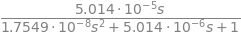

In [85]:
Y0 = s*C0 / (R0*C0*s + L0*C0*s**2 + 1)
Y0

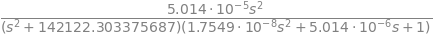

In [94]:
f = E*sympy.cos(w_fund*t)
F = sympy.laplace_transform(f, t, s, noconds=True)
SAIDA = F*Y0
SAIDA

In [127]:
saida = sympy.inverse_laplace_transform(SAIDA, s, t)
saida = saida/sympy.Heaviside(t)
saida

In [128]:
saida_num = sympy.lambdify(t, saida)


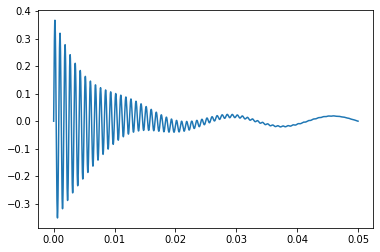

In [130]:
t_num = numpy.linspace(0, 0.05, 10000)
yyy = saida_num(t_num)
plt.plot(t_num, yyy)

In [23]:

# Vp = 19919


In [67]:
sys = signal.TransferFunction([C0, 0], [L0*C0, R0*C0, 1])
freqs = np.linspace(10, 10000, 10000)
omegas = 2*np.pi*freqs
w, mag, phase = signal.bode(sys, w=omegas)

In [68]:
polos = signal.ZerosPolesGain(sys).poles
w0 = polos.imag[0]
f0 = w0 / (2*np.pi)
f0

1201.2023163196095

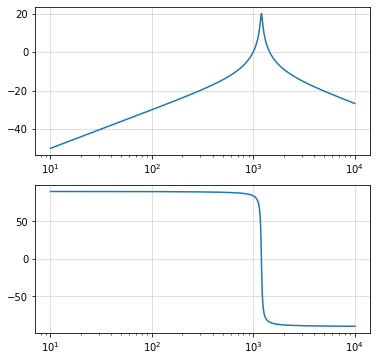

In [69]:
fig, ax = plt.subplots(nrows=2, ncols=1, figsize=(6,6))
freq = w/(2*np.pi)
ax[0].semilogx(freq, mag)
# ax[0].scatter(f0, mag.max())
ax[0].grid(alpha=0.5)
ax[1].semilogx(freq, phase) 
ax[1].grid(alpha=0.5)
plt.show()

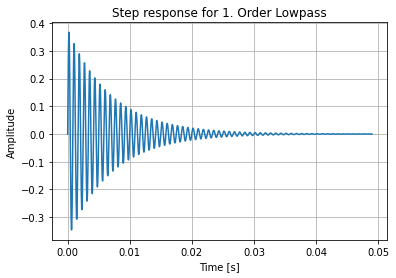

In [71]:
t, y = signal.step(sys, N=10000)
plt.plot(t, y)
plt.xlabel('Time [s]')
plt.ylabel('Amplitude')
plt.title('Step response for 1. Order Lowpass')
plt.grid()

(array([], dtype=int64),)

In [ ]:
import sympy as sp
sp.init_printing()
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
s, t, w, Vp = sp.symbols("s t omega V_p", positive=True)

In [ ]:
R0, R1, R2, R3, R4, R5, R6= sp.symbols("R_0 R_1 R_2 R_3 R_4 R_5 R_6", positive=True, complex=True)
L0, L1, L2, L3, L4, L5, L6= sp.symbols("L_0 L_1 L_2 L_3 L_4 L_5 L_6", positive=True, complex=True)
C0, C1, C2, C3, C4, C5, C6= sp.symbols("C_0 C_1 C_2 C_3 C_4 C_5 C_6", positive=True, complex=True)
Q0, Q1, Q2, Q3, Q4, Q5, Q6= sp.symbols("Q_0 Q_1 Q_2 Q_3 Q_4 Q_5 Q_6", positive=True, complex=True)

In [ ]:
Zr = sp.symbols("s Z_r")
L0 = 350e-6
C0 = 50.14e-6
R0 = 0.1
Vp = 19919
w = 2*np.pi*60

Z0 = R0 + s*L0 + 1/(s*C0)
Z1 = R1 + s*L1 + 1/(s*C1)
Z2 = R2 + s*L2 + 1/(s*C2)
Z3 = R3 + s*L3 + 1/(s*C3)
Z4 = R4 + s*L4 + 1/(s*C4)
Z5 = R5 + s*L5 + 1/(s*C5)
Z6 = R6 + s*L6 + 1/(s*C6)

In [ ]:
Z0 = Z0.factor()
Z0

In [ ]:
Y0 = 1/Z0
num, den = sp.fraction(Y0)
num, den

In [ ]:
from sympy.physics.control.lti import TransferFunction
# from sympy.physics.control.control_plots import pole_zero_plot
tf = TransferFunction(num, den, s)
sp.physics.control.(tf)

In [ ]:
x = sp.Symbol('x')
sp.solvers.solve(Z0, s)

In [ ]:
sp.solvers.solve(Z0, s)

In [ ]:
V = sp.laplace_transform(Vp*sp.sin(w*t), t, s, noconds=True)
I0_impulso = sp.simplify(1 / Z0)
i0_impulso = sp.inverse_laplace_transform(I0_impulso, s, t)
I0 = sp.simplify(V / Z0)
i0 = sp.inverse_laplace_transform(I0, s, t)

In [ ]:
i0_num = sp.lambdify((t), i0)
i0_impulso_num = sp.lambdify((t), i0_impulso)
t_num = np.linspace(0, 5/60, 60*128)

In [ ]:
fig, ax = plt.subplots(figsize=(36 ,5), dpi=900)
ax.plot(1e3*t_num, np.real(i0_num(t_num)),          lw=1.0)
ax.plot(1e3*t_num, np.real(i0_impulso_num(t_num)),  lw=0.75, alpha=0.5)
ax.set_xlabel('$t$ [ms]')
ax.set_ylabel('$i$ [A]')
ax.set_title('Inrsuh banco isolado, $C=50.14e-6$F, $L=350e-6$H, $R = 0.1 \\Omega$ ')
fig.show()